# Reproduce numerical figure panels

Plot the released aggregate results without refitting the participant-level models. See the repository README for setup and data access.

## 1. Public paths and plotting settings

The repository root is discovered from the current directory and its parents. Set
`PUBLIC_ROOT` only if the kernel starts elsewhere. No private input paths are used.

In [1]:
# Aim: set public-only paths and a shared style; method: repository-relative lookup;
# output: input/output folders, palette and compact plotting/provenance helpers.
from pathlib import Path
from statistics import NormalDist
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, FuncFormatter
from IPython.display import display

PUBLIC_ROOT = None  # Optional: Path('/path/to/repo_sz_meditation_share')
SAVE_FIGURES = False
RUN_OMISSION_RANGE_SUMMARY = False  # A distinct summary display, not the published point cloud.
DPI = 300

if PUBLIC_ROOT is None:
    candidates = [Path.cwd(), *Path.cwd().parents]
    PUBLIC_ROOT = next((p for p in candidates if (p / 'data/source_data').is_dir()), None)
if PUBLIC_ROOT is None:
    raise FileNotFoundError('Open this notebook from the public repository or set PUBLIC_ROOT.')
PUBLIC_ROOT = Path(PUBLIC_ROOT).expanduser().resolve()
SOURCE = PUBLIC_ROOT / 'data/source_data'
OUTPUT = PUBLIC_ROOT / 'fig/public_reproduction'
if SAVE_FIGURES:
    OUTPUT.mkdir(parents=True, exist_ok=True)

MONTH_COLORS = {3: '#E69F00', 8: '#005AB5'}
MONTH_MARKERS = {3: 's', 8: 'o'}
ARM_COLORS = {'control': '#7fbc41', 'meditation': '#4393c3'}
ARM_OUTLINES = {'control': '#276419', 'meditation': '#2166ac'}
ARM_MARKERS = {'control': 's', 'meditation': 'o'}
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 13,
    'axes.labelsize': 14, 'axes.titlesize': 15,
    'xtick.labelsize': 12, 'ytick.labelsize': 12,
    'axes.linewidth': 1.1, 'svg.fonttype': 'none', 'pdf.fonttype': 42,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})
provenance = []

def read_public(relative, columns=(), optional=False):
    path = SOURCE / relative
    if not path.is_file():
        if optional:
            return None
        raise FileNotFoundError(f'Required released table is missing: data/source_data/{relative}')
    table = pd.read_csv(path)
    missing = sorted(set(columns) - set(table.columns))
    if missing:
        raise ValueError(f'{relative}: missing required columns {missing}')
    return table

def flag(values):
    return values.astype(str).str.strip().str.lower().isin(['true', '1', '1.0'])

def quiet_axes(ax, horizontal=True):
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color('#858b92')
    ax.tick_params(axis='y', length=0, pad=8)
    ax.grid(axis='x' if horizontal else 'y', linestyle=':', color='#d9dde1', linewidth=0.8)
    ax.set_axisbelow(True)

def plain_ticks(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:g}'.replace('-', '−')))

def month_handles():
    return [Line2D([], [], color=MONTH_COLORS[m], marker=MONTH_MARKERS[m],
                   markerfacecolor='white', markeredgewidth=2, markersize=8,
                   linewidth=2.5, label=f'{m} months') for m in [3, 8]]

def interval(ax, y, mean, low, high, month, linewidth=2.6, markersize=8):
    ax.hlines(y, low, high, color=MONTH_COLORS[month], linewidth=linewidth, zorder=2)
    ax.plot(mean, y, marker=MONTH_MARKERS[month], linestyle='none',
            color=MONTH_COLORS[month], markerfacecolor='white',
            markersize=markersize, markeredgewidth=2, zorder=3)

def common_limits(values, minimum=0.0):
    finite = np.asarray(values, dtype=float)
    finite = finite[np.isfinite(finite)]
    extent = max(float(np.abs(finite).max()), minimum, 0.05) * 1.08
    ticks = MaxNLocator(nbins=5, symmetric=True).tick_values(-extent, extent)
    return (float(ticks[0]), float(ticks[-1])), ticks

def record(panel, status, sources, filters, output_stem='', note=''):
    hashes = {p: hashlib.sha256((SOURCE / p).read_bytes()).hexdigest()
              for p in sources if (SOURCE / p).is_file()}
    provenance.append({
        'Panel': panel, 'Status': status, 'Source_files': '; '.join(sources),
        'Source_SHA256': json.dumps(hashes, sort_keys=True), 'Row_filter_or_transform': filters,
        'Output_stem': output_stem, 'Note': note,
    })

def save_panel(fig, stem, panel, sources, filters, note=''):
    if SAVE_FIGURES:
        for extension in ['svg', 'png']:
            fig.savefig(OUTPUT / f'{stem}.{extension}', dpi=DPI,
                        bbox_inches='tight', facecolor='white')
    record(panel, 'generated' if SAVE_FIGURES else 'displayed_only', sources, filters, stem, note)
    plt.show()

## 2. Input availability

The table lists the available aggregate inputs. Optional panels are skipped when their source tables are absent.

In [2]:
# Aim: disclose panel coverage; method: inspect only named public files;
# output: a compact availability table, without searching private directories.
availability_rows = [
    ('Figure 1: ATE estimate panel', ['clinical/ATE_results.csv'],
     'Aggregate estimate display; the original trajectory layout is separate.'),
    ('Figure 1: arm trajectories', ['figure_source/Figure1_clinical_trajectories.csv'],
     'Optional aggregate marginal means and pointwise intervals.'),
    ('Figure 2b: clinical coefficients', ['clpm/Supplementary_Table_CLPM_main.csv'],
     'Coefficient forest panel; published diagram layout is manual.'),
    ('Figure 2: mediation summary', ['figure_source/Figure2_mediation_summary.csv'],
     'Optional saved bootstrap summary; never inferred from rounded CLPM paths.'),
    ('Figure 3b: intrinsic contrasts', ['figure_source/Figure3b_intrinsic_network_contrasts.csv'],
     'Optional full local-measure contrast export.'),
    ('Figure 3c: EC trajectories', ['dcm/PEB_section3/PEB_contrasts.csv',
                                  'dcm/PEB_section3/Supplementary_EC_sensitivity_summary.csv'],
     'Full-PEB FD-adjusted means and credible intervals are already released.'),
    ('Figure 4: eight EC contrasts', ['dcm/PEB_section3/PEB_contrasts.csv',
                                   'dcm/PEB_section3/Selected_edge_dictionary.csv'],
     'Uses the saved shared-eight flags, not a new significance threshold.'),
    ('Figure 5b: neural coefficients', ['neural_clinical/Focused_CLPM_semopy_paths.csv'],
     'All 16 focal neural–clinical coefficients from the full model.'),
    ('Figure 5c: R² contributions', ['neural_clinical/Focused_CLPM_semopy_outcomes.csv'],
     'Sequential in-sample increments; no new fits.'),
    ('Figure 6: range summary only', ['neural_clinical/Focused_CLPM_semopy_LOO_summary.csv'],
     'Optional distinct display; no individual omission dots can be reconstructed.'),
]
availability = pd.DataFrame([
    {'Panel': panel, 'Available': all((SOURCE / p).is_file() for p in files),
     'Source_files': '; '.join(files), 'Coverage': note}
    for panel, files, note in availability_rows
])
display(availability)
display(pd.DataFrame([
    {'Panel': 'Figure 2a participant scatter', 'Coverage': 'No participant plotting input is released.'},
    {'Panel': 'Figure 3a workflow schematic', 'Coverage': 'Manually assembled; not generated here.'},
    {'Panel': 'Figures 3c/4 glass brains', 'Coverage': 'Current group IC maps are not supplied to this companion.'},
    {'Panel': 'Figure 5a neural CLPM diagram', 'Coverage': 'Manual diagram geometry is not rendered; fitted paths are available in neural_clinical/Focused_CLPM_semopy_paths.csv.'},
    {'Panel': 'Figure 6 original omission cloud', 'Coverage': 'Only ranges/counts are public, not 43 individual omission estimates.'},
]))

,Panel,Available,Source_files,Coverage
0,Figure 1: ATE estimate panel,True,clinical/ATE_results.csv,Aggregate estimate display; the original traje...
1,Figure 1: arm trajectories,True,figure_source/Figure1_clinical_trajectories.csv,Optional aggregate marginal means and pointwis...
2,Figure 2b: clinical coefficients,True,clpm/Supplementary_Table_CLPM_main.csv,Coefficient forest panel; published diagram la...
3,Figure 2: mediation summary,True,figure_source/Figure2_mediation_summary.csv,Optional saved bootstrap summary; never inferr...
4,Figure 3b: intrinsic contrasts,True,figure_source/Figure3b_intrinsic_network_contr...,Optional full local-measure contrast export.
5,Figure 3c: EC trajectories,True,dcm/PEB_section3/PEB_contrasts.csv; dcm/PEB_se...,Full-PEB FD-adjusted means and credible interv...
6,Figure 4: eight EC contrasts,True,dcm/PEB_section3/PEB_contrasts.csv; dcm/PEB_se...,"Uses the saved shared-eight flags, not a new s..."
7,Figure 5b: neural coefficients,True,neural_clinical/Focused_CLPM_semopy_paths.csv,All 16 focal neural–clinical coefficients from...
8,Figure 5c: R² contributions,True,neural_clinical/Focused_CLPM_semopy_outcomes.csv,Sequential in-sample increments; no new fits.
9,Figure 6: range summary only,True,neural_clinical/Focused_CLPM_semopy_LOO_summar...,Optional distinct display; no individual omiss...


,Panel,Coverage
0,Figure 2a participant scatter,No participant plotting input is released.
1,Figure 3a workflow schematic,Manually assembled; not generated here.
2,Figures 3c/4 glass brains,Current group IC maps are not supplied to this...
3,Figure 5a neural CLPM diagram,Manual diagram geometry is not rendered; fitte...
4,Figure 6 original omission cloud,"Only ranges/counts are public, not 43 individu..."


## 3. Load the released result tables

Names and the two focal connections are taken from the saved naming/sensitivity tables.
Model labels follow the manuscript: **M0** clinical; **M1** clinical + motion;
**M2** M1 + two baseline ECs; **M3** M2 + two early EC changes.

In [3]:
# Aim: prepare plotting tables; method: read released model exports and saved selection flags;
# output: named nodes, fixed reporting order and the four CLPM model identifiers.
FILES = {
    'ate': 'clinical/ATE_results.csv',
    'clinical': 'clpm/Supplementary_Table_CLPM_main.csv',
    'contrasts': 'dcm/PEB_section3/PEB_contrasts.csv',
    'edges': 'dcm/PEB_section3/Selected_edge_dictionary.csv',
    'sensitivity': 'dcm/PEB_section3/Supplementary_EC_sensitivity_summary.csv',
    'names': 'Section3_IC_naming/IC_naming_rationale.csv',
    'paths': 'neural_clinical/Focused_CLPM_semopy_paths.csv',
    'outcomes': 'neural_clinical/Focused_CLPM_semopy_outcomes.csv',
    'loo': 'neural_clinical/Focused_CLPM_semopy_LOO_summary.csv',
}
ate = read_public(FILES['ate'])
clinical_paths = read_public(FILES['clinical'], ['lval', 'op', 'rval', 'Estimate', 'Est. Std', 'Std. Err'])
peb = read_public(FILES['contrasts'], ['Model', 'Contrast', 'Source_Node', 'Target_Node',
                                    'FullPEB_mean_Hz', 'FullPEB_CrI95_low_Hz', 'FullPEB_CrI95_high_Hz'])
edge_dictionary = read_public(FILES['edges'], ['Source_Node', 'Target_Node', 'Selected_both'])
sensitivity = read_public(FILES['sensitivity'], ['Source_Node', 'Target_Node', 'Focal_edge'])
names = read_public(FILES['names'], ['Node_ID', 'IC_ID', 'Display_name'])
sem_paths = read_public(FILES['paths'], ['Model', 'lval', 'rval', 'op', 'Beta',
                                      'SEM_CI95_low_Beta_plugin', 'SEM_CI95_high_Beta_plugin'])
sem_outcomes = read_public(FILES['outcomes'], ['Model', 'Outcome', 'In_sample_R2', 'Adjusted_R2'])
loo_summary = read_public(FILES['loo'], optional=True)
node_labels = (names['IC_ID'] + ' ' + names['Display_name']).set_axis(names['Node_ID']).to_dict()

def edge_label(edge):
    return f'{node_labels[edge[0]]} → {node_labels[edge[1]]}'

preferred_edges = [
    ('IC02_SalVentA', 'IC00_SMN'), ('IC02_SalVentA', 'IC04_Vis_V1'),
    ('IC02_SalVentA', 'IC18_SalVentB'), ('IC04_Vis_V1', 'IC00_SMN'),
    ('IC04_Vis_V1', 'IC09_pDMN'), ('IC15_DAN', 'IC05_aDMN'),
    ('IC18_SalVentB', 'IC05_aDMN'), ('IC19_ECN', 'IC05_aDMN'),
]
shared_edges = list(edge_dictionary.loc[flag(edge_dictionary['Selected_both']),
                                     ['Source_Node', 'Target_Node']].itertuples(index=False, name=None))
if len(shared_edges) != 8 or len(set(shared_edges)) != 8:
    raise ValueError('This figure expects exactly eight unique saved shared ECs; review the exported dictionary.')
edge_order = [edge for edge in preferred_edges if edge in shared_edges]
edge_order += [edge for edge in shared_edges if edge not in edge_order]
focal_set = set(sensitivity.loc[flag(sensitivity['Focal_edge']),
                                ['Source_Node', 'Target_Node']].itertuples(index=False, name=None))
focal_edges = [edge for edge in edge_order if edge in focal_set]
if len(focal_set) != 2 or len(focal_edges) != 2:
    raise ValueError('This figure expects exactly two focal ECs within the shared-eight set; review the saved flags.')
MODELS = {'M0': '0_Clinical_original_covariates', 'M1': '1_Clinical+FD',
          'M2': '2_Two_baselines', 'M3': '3_Two_early_changes'}
OUTCOME_LABELS = {'PANSS_dec_rate_3': 'PDR3', 'PANSS_dec_rate_8': 'PDR8',
                  'RBANS_inc_rate_3': 'RIR3', 'RBANS_inc_rate_8': 'RIR8'}
NEURAL_EDGES = [('SalVentA_to_SMN', ('IC02_SalVentA', 'IC00_SMN')),
                ('SalVentA_to_SalVentB', ('IC02_SalVentA', 'IC18_SalVentB'))]
NEURAL_OUTCOMES = ['RBANS_inc_rate_3', 'PANSS_dec_rate_3',
                   'PANSS_dec_rate_8', 'RBANS_inc_rate_8']
FAMILIES = [('Baseline EC', 'EC0_'), ('Early EC change (0–3 months)', 'D3_')]
display(pd.DataFrame({'Model': list(MODELS), 'Saved_identifier': list(MODELS.values())}))

,Model,Saved_identifier
0,M0,0_Clinical_original_covariates
1,M1,1_Clinical+FD
2,M2,2_Two_baselines
3,M3,3_Two_early_changes


## 4. Clinical treatment estimates supporting Figure 1

This compact estimate panel is an additional view of the released ATE table. It does not
replace the original arm trajectories. The unit is the absolute difference in the improvement
rate multiplied by 100: **percentage points**. Existing 95% model-based intervals are preserved.

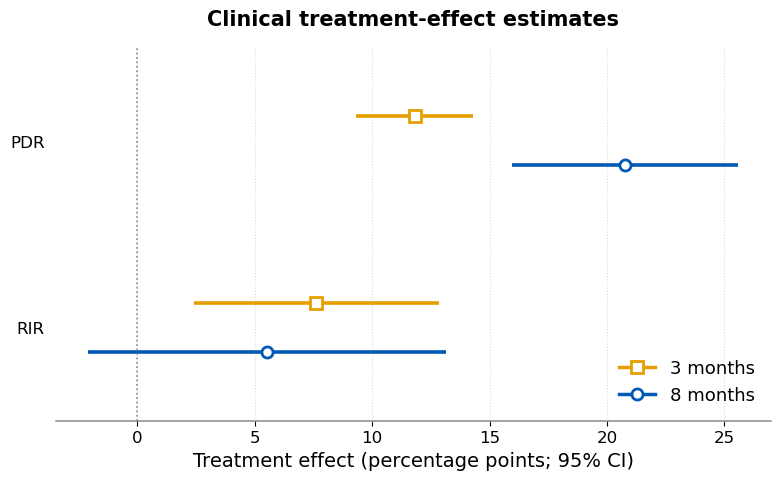

In [4]:
# Aim: display saved clinical ATEs; method: use exported percentage-point contrasts and CIs;
# output: an explicitly labelled aggregate estimate panel, with no clinical model refitting.
fig1a_size = (8, 5)
fig1a_outcomes = ['PDR', 'RIR']
fig1a_rows = ate.loc[ate['Outcome'].isin(fig1a_outcomes)].copy()
fig1a_counts = fig1a_rows.groupby(['Outcome', 'Month']).size()
if any(fig1a_counts.get((outcome, month), 0) != 1
       for outcome in fig1a_outcomes for month in [3, 8]):
    raise ValueError('The ATE panel needs one saved row for each requested outcome and visit.')
fig, ax = plt.subplots(figsize=fig1a_size)
for j, outcome in enumerate(fig1a_outcomes):
    for month, shift in [(3, -0.13), (8, 0.13)]:
        row = fig1a_rows.loc[(fig1a_rows['Outcome'] == outcome) &
                            (fig1a_rows['Month'] == month)].iloc[0]
        interval(ax, j + shift, row['Estimate_percentage_points'],
                 row['CI95_low_percentage_points'], row['CI95_high_percentage_points'], month)
ax.set_yticks(range(len(fig1a_outcomes)), fig1a_outcomes)
ax.set_ylim(1.5, -0.5)
ax.axvline(0, color='#858b92', linestyle=':', linewidth=1.2)
ax.set_xlabel('Treatment effect (percentage points; 95% CI)')
ax.set_title('Clinical treatment-effect estimates', fontweight='bold', pad=16)
ax.legend(handles=month_handles(), frameon=False, loc='lower right')
quiet_axes(ax)
fig.tight_layout()
save_panel(fig, 'Figure1_ATE_estimate_summary', 'Figure 1: estimate summary', [FILES['ate']],
           'Outcome in PDR/RIR; Month in 3/8; exported percentage-point columns',
           'Additional aggregate estimate display, not the original trajectory panel.')

## 5. clinical arm trajectories

Run this after the author has released `Figure1_clinical_trajectories.csv`. Connecting the three
scheduled visits is a visual guide. Marginal means and their intervals come directly from the
saved export; treatment contrasts are supplied separately by the ATE table.

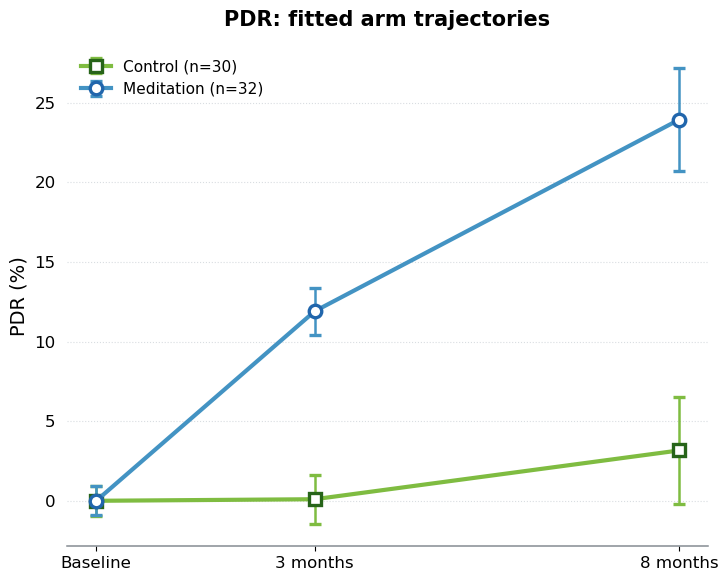

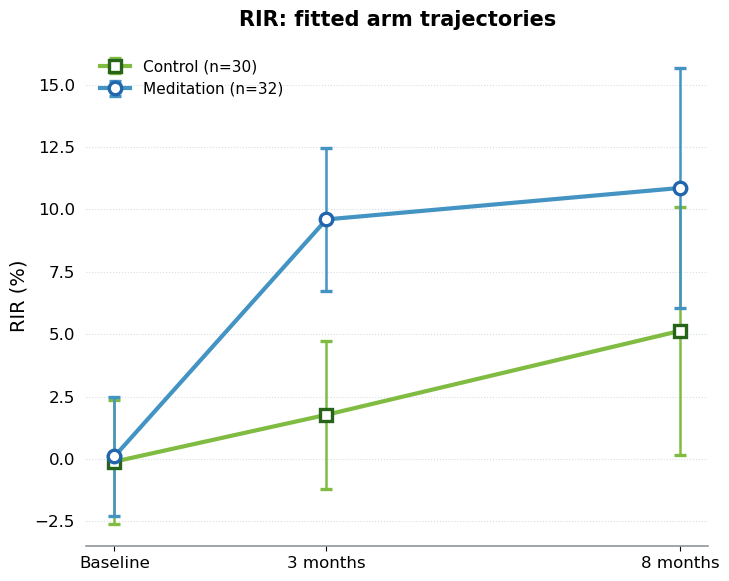

In [5]:
# Aim: reproduce clinical arm trajectories when exported; method: plot saved marginal means;
# output: separate PDR/RIR SVG and PNG panels, or an explicit missing-input note.
fig1t_file = 'figure_source/Figure1_clinical_trajectories.csv'
fig1t = read_public(fig1t_file, ['Outcome', 'Group', 'Month', 'Group_N',
                              'Mean_percent', 'CI95_low_percent', 'CI95_high_percent'], optional=True)
if fig1t is None:
    print('Figure 1 trajectories unavailable: release the aggregate marginal-mean export first.')
    record('Figure 1: arm trajectories', 'missing_optional_input', [fig1t_file], 'PDR/RIR only')
else:
    for outcome in ['PDR', 'RIR']:
        fig, ax = plt.subplots(figsize=(7.5, 6))
        for group in ['control', 'meditation']:
            part = fig1t.loc[fig1t.Outcome.eq(outcome) & fig1t.Group.eq(group)].sort_values('Month')
            means = part['Mean_percent'].to_numpy()
            error = np.vstack([means - part['CI95_low_percent'], part['CI95_high_percent'] - means])
            counts = sorted(part['Group_N'].dropna().astype(int).unique())
            nlabel = f'n={counts[0]}' if len(counts) == 1 else 'n by visit: ' + '/'.join(map(str, part['Group_N'].astype(int)))
            ax.errorbar(part['Month'], means, yerr=error, color=ARM_COLORS[group],
                        marker=ARM_MARKERS[group], markerfacecolor='white',
                        markeredgecolor=ARM_OUTLINES[group], markeredgewidth=2.4,
                        linewidth=3, elinewidth=1.8, markersize=9, capsize=4,
                        label=f'{group.capitalize()} ({nlabel})')
        ax.set_xticks([0, 3, 8], ['Baseline', '3 months', '8 months'])
        ax.set_ylabel(f'{outcome} (%)')
        ax.set_title(f'{outcome}: fitted arm trajectories', fontweight='bold', pad=14)
        ax.legend(frameon=False, fontsize=11)
        quiet_axes(ax, horizontal=False)
        fig.tight_layout()
        save_panel(fig, f'Figure1_{outcome}_trajectories', 'Figure 1: arm trajectories',
                   [fig1t_file], f'Outcome={outcome}; each Group; sorted by Month',
                   'Exported pointwise marginal-mean CIs; rates multiplied by 100.')

## 6. Clinical CLPM coefficients supporting Figure 2b

All four treatment-to-outcome paths and all four clinical lag paths are shown, regardless of
nominal significance. Native coefficient SEs are rescaled using the saved standardized-to-raw
coefficient ratio to form **plug-in Wald intervals with the scale held fixed**. The optional
mediation table is a separate saved bootstrap summary; its interval is not reconstructed here.

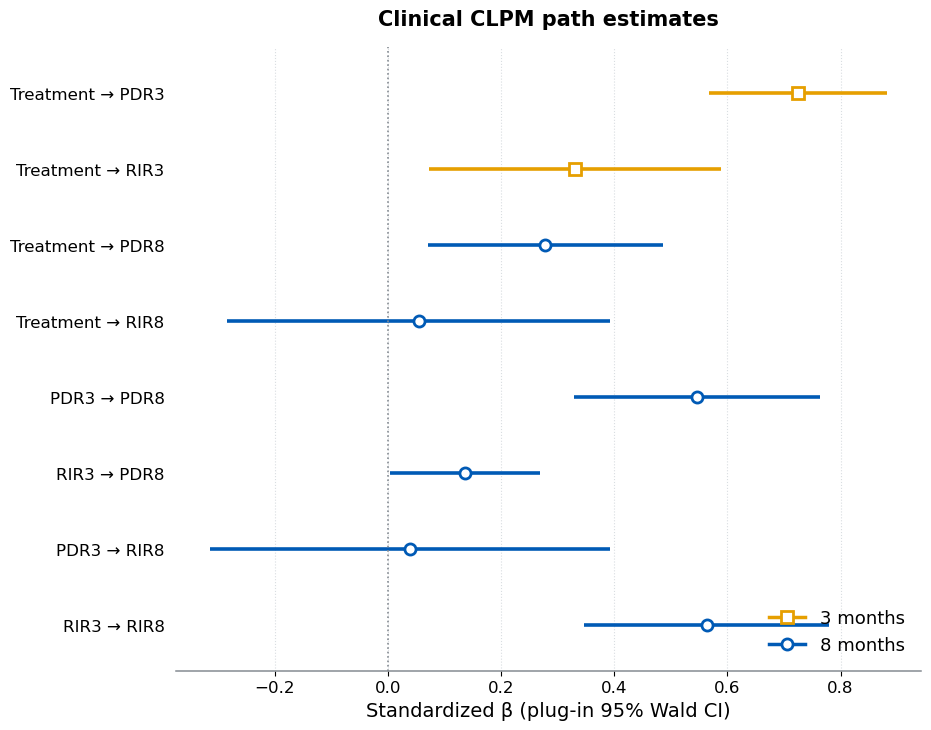

,Path,A_path_common_input_SD_scale,B_path_common_input_SD_scale,Indirect_estimate_common_input_SD_scale,Percentile_CI95_low,Percentile_CI95_high,Interval_method,N_boot_requested,N_boot_nonmissing,N_resampling_frame_rows,N_equation_a,N_equation_b,Equations_use_same_rows,Equation_a,Equation_b,Scaled_variables,Standardization
0,treatment -> RBANS_inc_rate_3 -> PANSS_dec_rate_8,0.315106,0.135827,0.0428,-0.015278,0.149895,"Bootstrap percentile, 2.5th and 97.5th percent...",10000,10000,64,63,62,False,RBANS_inc_rate_3 ~ treatment + PANSS_SUM_base ...,PANSS_dec_rate_8 ~ RBANS_inc_rate_3 + PANSS_de...,treatment; RBANS_inc_rate_3; PANSS_dec_rate_8;...,StandardScaler: center and divide each column ...


In [6]:
# Aim: show clinical graph coefficients; method: saved standardized estimates plus native SEs;
# output: an eight-path coefficient panel and, if available, the actual mediation summary.
fig2_order = [
    ('PANSS_dec_rate_3', 'treatment'), ('RBANS_inc_rate_3', 'treatment'),
    ('PANSS_dec_rate_8', 'treatment'), ('RBANS_inc_rate_8', 'treatment'),
    ('PANSS_dec_rate_8', 'PANSS_dec_rate_3'), ('PANSS_dec_rate_8', 'RBANS_inc_rate_3'),
    ('RBANS_inc_rate_8', 'PANSS_dec_rate_3'), ('RBANS_inc_rate_8', 'RBANS_inc_rate_3'),
]
fig2_rows = clinical_paths.loc[clinical_paths.op.eq('~')].set_index(['lval', 'rval']).loc[fig2_order].copy()
fig2_rows[['Estimate', 'Est. Std', 'Std. Err']] = fig2_rows[['Estimate', 'Est. Std', 'Std. Err']].apply(pd.to_numeric)
if fig2_rows['Estimate'].eq(0).any():
    raise ValueError('A zero raw coefficient prevents recovering the beta rescaling from this export.')
fig2_scale = (fig2_rows['Est. Std'] / fig2_rows['Estimate']).abs()
fig2_halfwidth = NormalDist().inv_cdf(0.975) * fig2_rows['Std. Err'] * fig2_scale
fig2_rows['CI_low'] = fig2_rows['Est. Std'] - fig2_halfwidth
fig2_rows['CI_high'] = fig2_rows['Est. Std'] + fig2_halfwidth
fig, ax = plt.subplots(figsize=(9.5, 7.5))
fig2_labels = []
for j, ((outcome, predictor), row) in enumerate(fig2_rows.iterrows()):
    interval(ax, j, row['Est. Std'], row['CI_low'], row['CI_high'], int(outcome[-1]))
    fig2_labels.append(f'{OUTCOME_LABELS.get(predictor, "Treatment")} → {OUTCOME_LABELS[outcome]}')
ax.set_yticks(range(len(fig2_labels)), fig2_labels)
ax.set_ylim(len(fig2_labels) - 0.4, -0.6)
ax.axvline(0, color='#858b92', linestyle=':', linewidth=1.2)
ax.set_xlabel('Standardized β (plug-in 95% Wald CI)')
ax.set_title('Clinical CLPM path estimates', fontweight='bold', pad=16)
ax.legend(handles=month_handles(), frameon=False, loc='lower right')
quiet_axes(ax)
fig.tight_layout()
save_panel(fig, 'Figure2b_clinical_CLPM_coefficients', 'Figure 2b: coefficient panel',
           [FILES['clinical']], 'op=~; four treatment and four clinical lag paths; CI uses saved SE × |Est.Std/Estimate|',
           'Diagram coefficients displayed as a forest panel; native nonrobust Wald uncertainty, fixed plug-in scale.')

fig2m_file = 'figure_source/Figure2_mediation_summary.csv'
fig2m = read_public(fig2m_file, ['Path', 'Indirect_estimate_common_input_SD_scale',
                              'Percentile_CI95_low', 'Percentile_CI95_high'], optional=True)
if fig2m is None:
    print('Mediation annotation unavailable: the saved bootstrap-summary export is not present.')
    record('Figure 2: mediation summary', 'missing_optional_input', [fig2m_file], 'No reconstruction')
else:
    display(fig2m)
    record('Figure 2: mediation summary', 'displayed_table', [fig2m_file], 'All saved rows',
           note='Saved OLS product/percentile bootstrap summary; distinct from rounded diagram-path products.')

## 7. Optional intrinsic-network contrast panel (Figure 3b)

The export preserves all components, metrics and visits; the panel does not select rows using
their p-values. `Network_plot_y=0` remains the bottom row, following the original notebook.

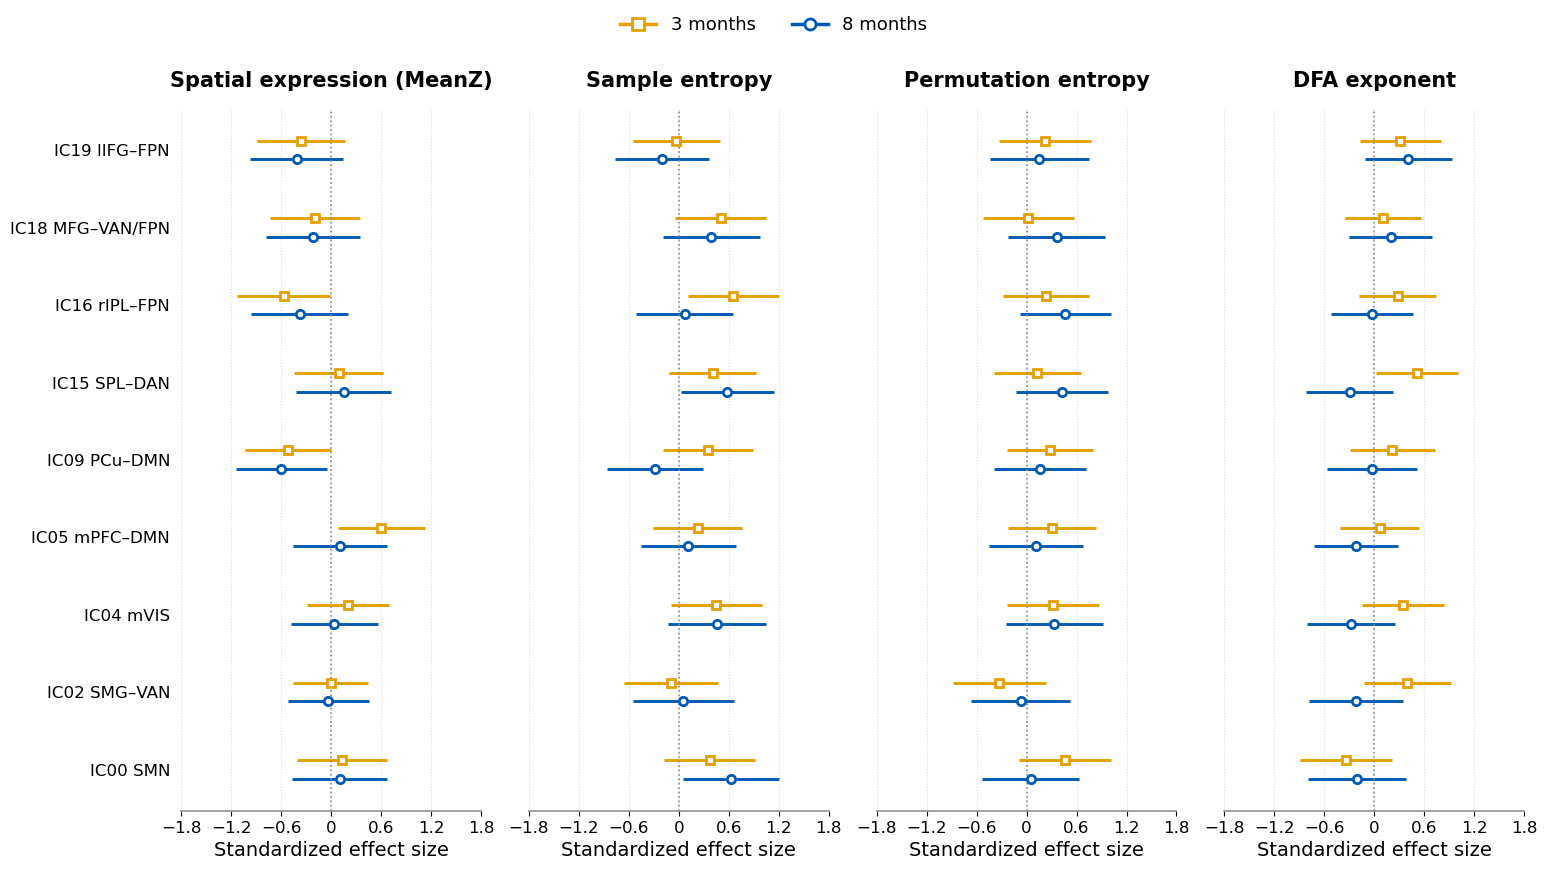

In [7]:
# Aim: reproduce all local-network contrasts; method: use the optional final forest-plot export;
# output: the four-metric panel when available, preserving native intervals and original order.
fig3b_file = 'figure_source/Figure3b_intrinsic_network_contrasts.csv'
fig3b = read_public(fig3b_file, ['Metric', 'Metric_label', 'Metric_plot_order', 'Network',
                                'Network_label', 'Network_plot_y', 'Month', 'Estimate',
                                'CI95_low', 'CI95_high'], optional=True)
if fig3b is None:
    print('Figure 3b unavailable: release the final aggregate intrinsic-network contrast export first.')
    record('Figure 3b', 'missing_optional_input', [fig3b_file], 'All metrics, components and visits')
else:
    metric_order = fig3b[['Metric', 'Metric_label', 'Metric_plot_order']].drop_duplicates().sort_values('Metric_plot_order')
    network_order = fig3b[['Network', 'Network_label', 'Network_plot_y']].drop_duplicates().sort_values('Network_plot_y')
    limits, ticks = common_limits(fig3b[['CI95_low', 'CI95_high']].to_numpy())
    fig, axes = plt.subplots(1, len(metric_order), figsize=(17, 9), sharey=True, squeeze=False)
    for ax, metric in zip(axes.flat, metric_order.itertuples(index=False)):
        part = fig3b.loc[fig3b.Metric.eq(metric.Metric)]
        for row in part.itertuples(index=False):
            month = int(row.Month)
            interval(ax, row.Network_plot_y + (0.12 if month == 3 else -0.12),
                     row.Estimate, row.CI95_low, row.CI95_high, month, linewidth=2.1, markersize=6)
        ax.set_title(metric.Metric_label, fontweight='bold', pad=16)
        ax.set_xlim(limits)
        ax.set_xticks(ticks)
        plain_ticks(ax)
        ax.axvline(0, color='#858b92', linestyle=':', linewidth=1.2)
        ax.set_xlabel('Standardized effect size')
        quiet_axes(ax)
    axes[0, 0].set_yticks(network_order.Network_plot_y, network_order.Network_label)
    fig.legend(handles=month_handles(), loc='upper center', ncol=2, frameon=False)
    fig.subplots_adjust(left=0.19, right=0.98, top=0.88, bottom=0.10, wspace=0.16)
    save_panel(fig, 'Figure3b_intrinsic_network_contrasts', 'Figure 3b', [fig3b_file],
               'All rows; source Metric_plot_order and Network_plot_y; no p-value filtering',
               'Saved pointwise native Wald intervals; existing FDR values remain in the source table.')

## 8. Two focal motion-adjusted EC trajectories (Figure 3c)

Each panel uses full-PEB group means at the three scheduled visits, with pointwise 95% credible
intervals (CrIs). Both panels share a vertical scale. Focal status comes from the released
sensitivity summary, and group sizes come from the aggregate contrast table. The optional
duplicate trajectory export is not needed.

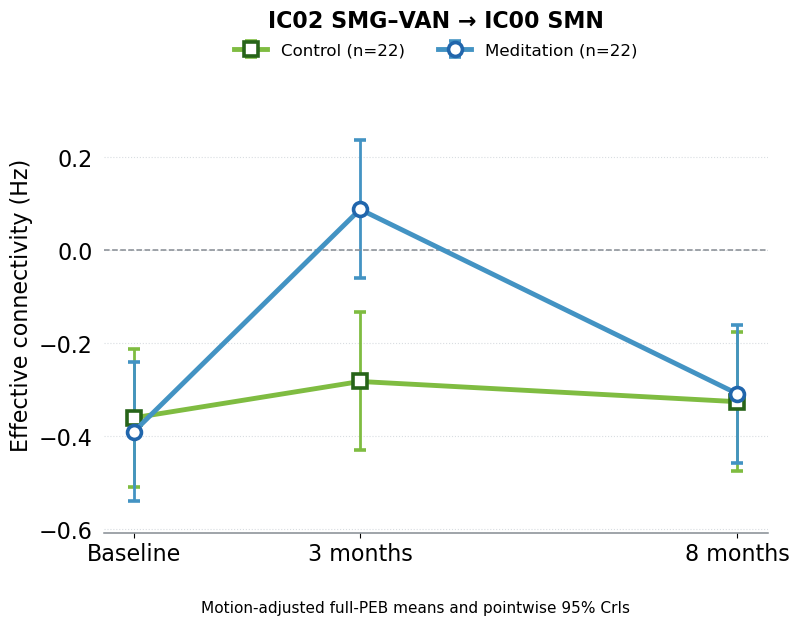

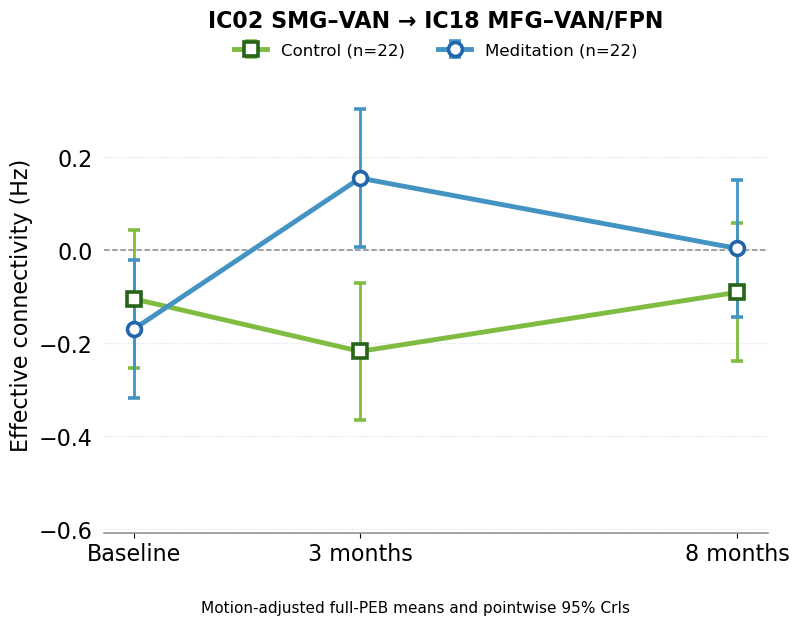

In [8]:
# Aim: reproduce the two focal EC trajectories; method: filter saved FD-adjusted PEB means;
# output: two separate trajectory panels, suitable for manual figure assembly.
fig3c_size = (8, 7)
fig3c_font = 16
fig3c = peb.loc[peb.Model.eq('FD_adjusted') & peb.Contrast.eq('Fitted_group_mean')].copy()
fig3c_focal_mask = pd.Series(list(zip(fig3c.Source_Node, fig3c.Target_Node)), index=fig3c.index).isin(focal_edges)
fig3c_bounds = fig3c.loc[fig3c_focal_mask, ['FullPEB_CrI95_low_Hz', 'FullPEB_CrI95_high_Hz']].to_numpy()
fig3c_low, fig3c_high = min(0, np.nanmin(fig3c_bounds)), max(0, np.nanmax(fig3c_bounds))
fig3c_pad = 0.08 * (fig3c_high - fig3c_low)
for edge in focal_edges:
    fig, ax = plt.subplots(figsize=fig3c_size)
    for group in ['control', 'meditation']:
        part = fig3c.loc[fig3c.Source_Node.eq(edge[0]) & fig3c.Target_Node.eq(edge[1]) &
                        fig3c.Group.eq(group)].sort_values('End_month')
        mean = part['FullPEB_mean_Hz'].to_numpy()
        errors = np.vstack([mean - part['FullPEB_CrI95_low_Hz'], part['FullPEB_CrI95_high_Hz'] - mean])
        n = int(part['Control_N' if group == 'control' else 'Meditation_N'].iloc[0])
        ax.errorbar(part['End_month'], mean, yerr=errors, color=ARM_COLORS[group],
                    marker=ARM_MARKERS[group], markerfacecolor='white',
                    markeredgecolor=ARM_OUTLINES[group], markeredgewidth=2.6,
                    linewidth=3.5, elinewidth=2, markersize=10, capsize=4,
                    label=f'{group.capitalize()} (n={n})')
    ax.set_xticks([0, 3, 8], ['Baseline', '3 months', '8 months'])
    ax.set_xlim(-0.4, 8.4)
    ax.set_ylim(fig3c_low - fig3c_pad, fig3c_high + fig3c_pad)
    ax.tick_params(labelsize=fig3c_font)
    ax.set_ylabel('Effective connectivity (Hz)', fontsize=fig3c_font)
    ax.axhline(0, color='#858b92', linestyle='--', linewidth=1.1)
    ax.set_title(edge_label(edge), fontsize=fig3c_font, fontweight='bold', pad=36)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False, fontsize=12)
    quiet_axes(ax, horizontal=False)
    fig.subplots_adjust(left=0.15, right=0.98, bottom=0.17, top=0.82)
    fig.text(0.54, 0.055, 'Motion-adjusted full-PEB means and pointwise 95% CrIs', ha='center', fontsize=11)
    save_panel(fig, f'Figure3c_{edge[0][:4]}_to_{edge[1][:4]}_FD_trajectory', 'Figure 3c: EC trajectory',
               [FILES['contrasts'], FILES['sensitivity'], FILES['names']],
               f'Model=FD_adjusted; Contrast=Fitted_group_mean; edge={edge}; Group=control/meditation; End_month=0/3/8',
               'Focal_edge flag supplies the reporting choice; all fitted temporal terms contribute to these means.')

## 9. Eight shared EC contrasts (Figure 4 numerical panels)

The eight edges are defined by the **saved `Selected_both` flag**, not selected again using the
displayed intervals. The contrast is meditation minus control in change from baseline to the
specified visit. These full-PEB pointwise CrIs and the PEB selection probabilities describe
different quantities. This block exports individual forest panels plus a compact 4×2 assembly;
the glass-brain assets require separately released group component maps.

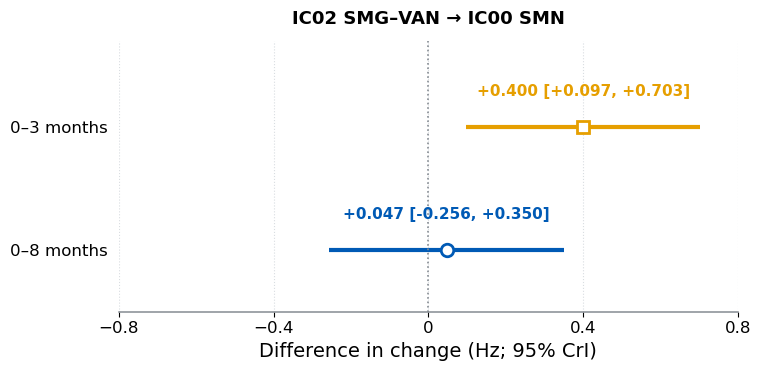

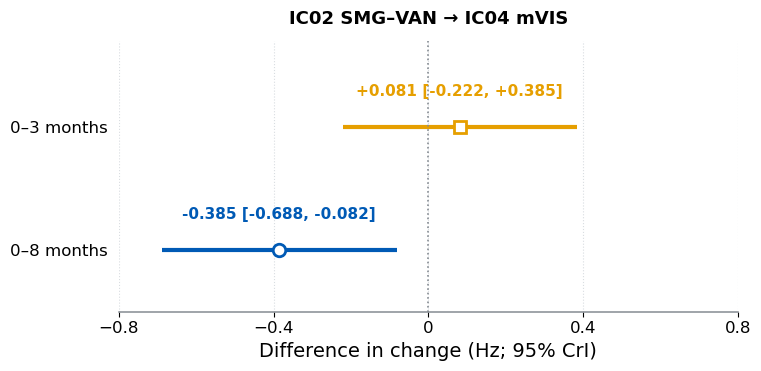

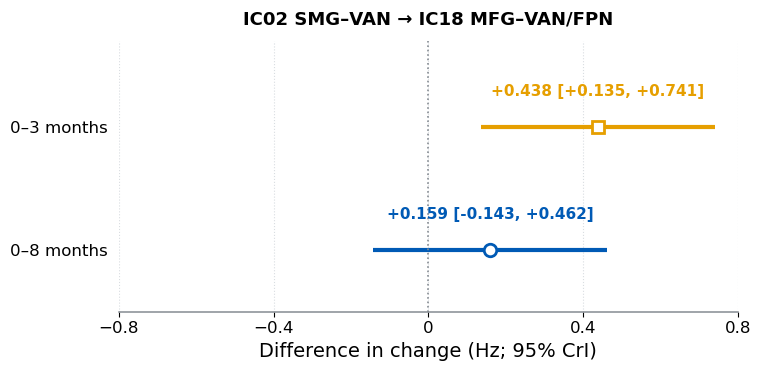

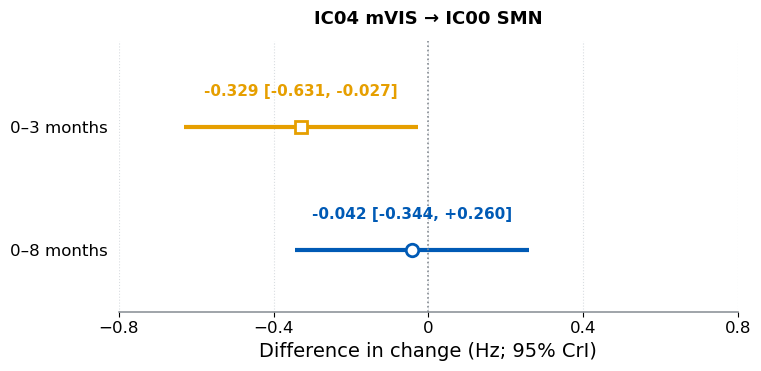

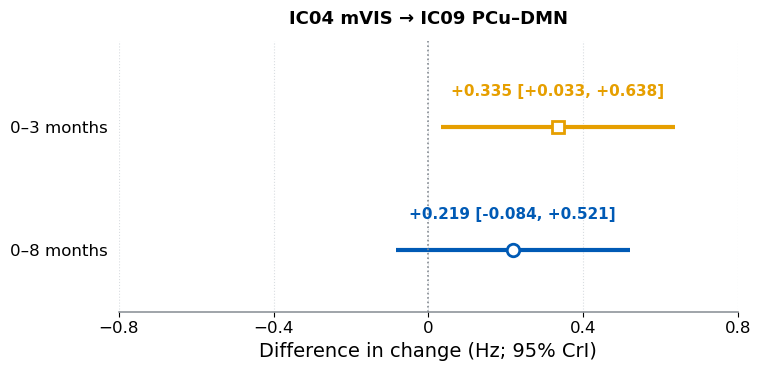

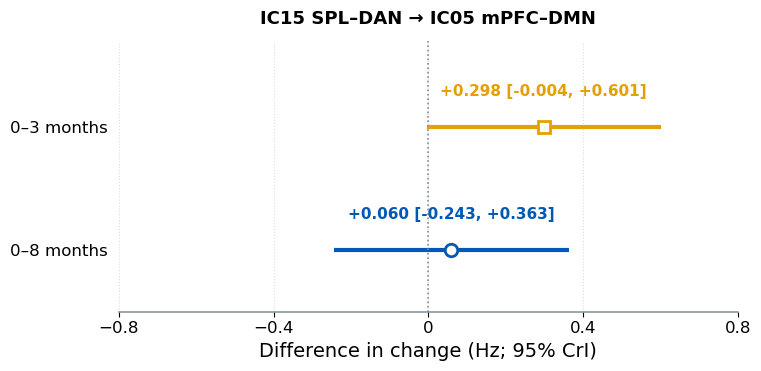

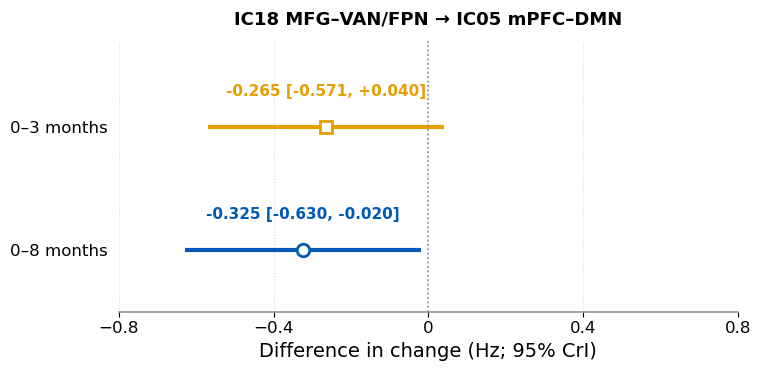

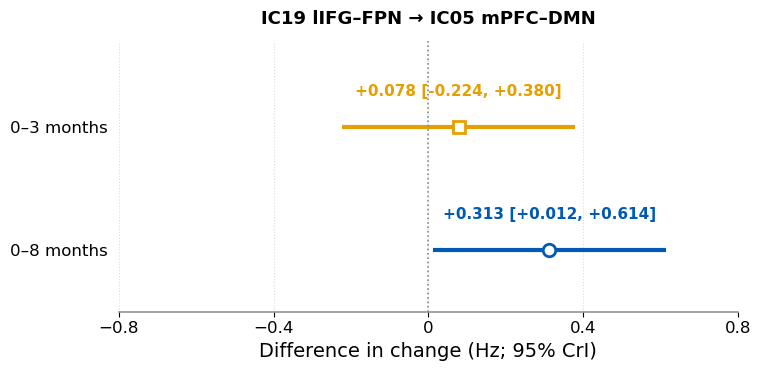

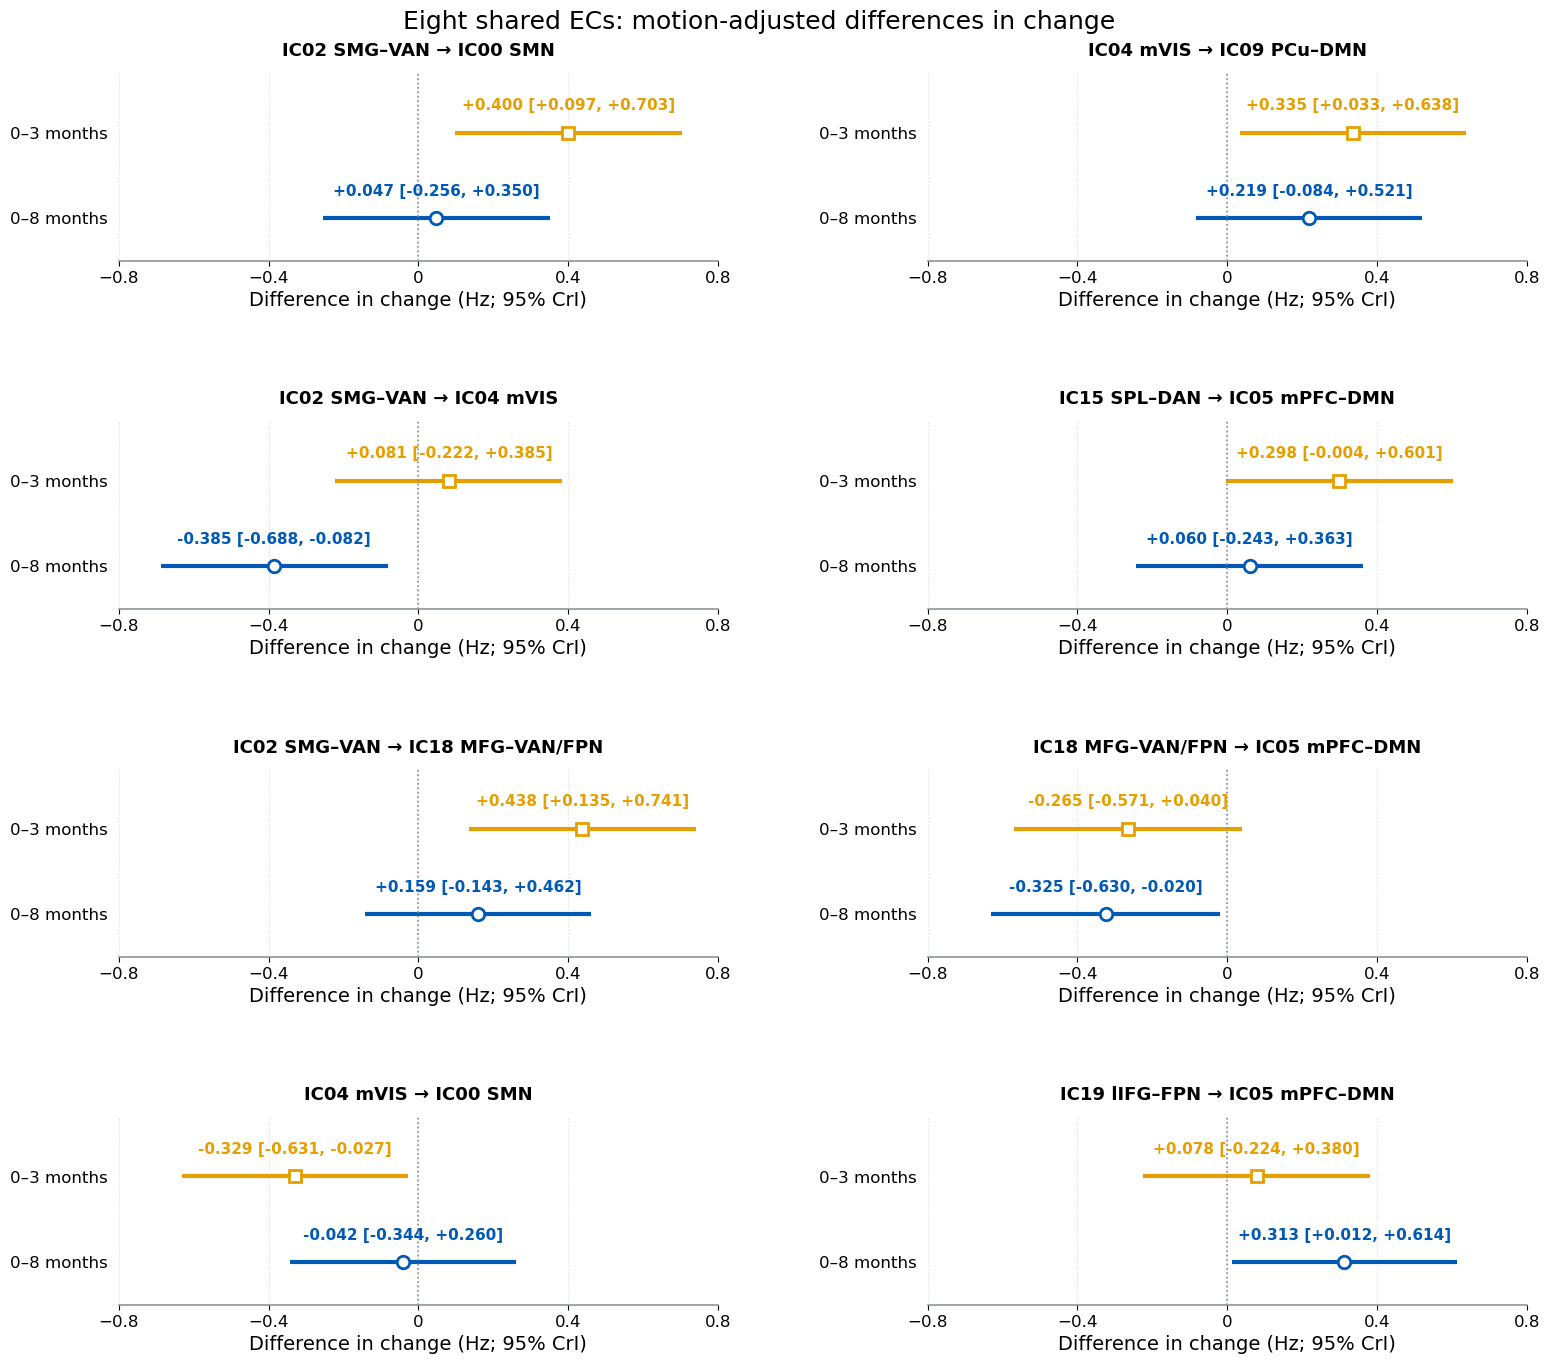

In [9]:
# Aim: reproduce all eight EC contrast panels; method: saved shared-edge membership and FD contrasts;
# output: separate numerical panels and a 4×2 assembly, without glass-brain placeholders.
fig4 = peb.loc[peb.Model.eq('FD_adjusted') & peb.Contrast.eq('Group_difference_in_change') &
               peb.End_month.isin([3, 8])].copy()
fig4_mask = pd.Series(list(zip(fig4.Source_Node, fig4.Target_Node)), index=fig4.index).isin(edge_order)
fig4 = fig4.loc[fig4_mask]
fig4_xlim, fig4_ticks = common_limits(fig4[['FullPEB_CrI95_low_Hz', 'FullPEB_CrI95_high_Hz']].to_numpy())

def draw_ec_contrasts(ax, edge):
    part = fig4.loc[fig4.Source_Node.eq(edge[0]) & fig4.Target_Node.eq(edge[1])].set_index('End_month')
    for month, y in [(3, 1), (8, 0)]:
        row = part.loc[month]
        mean, low, high = row[['FullPEB_mean_Hz', 'FullPEB_CrI95_low_Hz', 'FullPEB_CrI95_high_Hz']].astype(float)
        interval(ax, y, mean, low, high, month, linewidth=3, markersize=9)
        ax.text(mean, y + 0.23, f'{mean:+.3f} [{low:+.3f}, {high:+.3f}]',
                ha='center', va='bottom', color=MONTH_COLORS[month], fontsize=11, fontweight='bold')
    ax.set_yticks([1, 0], ['0–3 months', '0–8 months'])
    ax.set_ylim(-0.5, 1.7)
    ax.set_xlim(fig4_xlim)
    ax.set_xticks(fig4_ticks)
    plain_ticks(ax)
    ax.axvline(0, color='#858b92', linestyle=':', linewidth=1.2)
    ax.set_xlabel('Difference in change (Hz; 95% CrI)')
    ax.set_title(edge_label(edge), fontweight='bold', fontsize=13, pad=12)
    quiet_axes(ax)

for edge in edge_order:
    fig, ax = plt.subplots(figsize=(7.8, 3.9))
    draw_ec_contrasts(ax, edge)
    fig.tight_layout()
    save_panel(fig, f'Figure4_{edge[0][:4]}_to_{edge[1][:4]}_contrast', 'Figure 4: EC contrast',
               [FILES['contrasts'], FILES['edges'], FILES['names']],
               f'Selected_both=True; Model=FD_adjusted; Contrast=Group_difference_in_change; edge={edge}; months=3/8',
               'Full-PEB pointwise CrIs; not BMA or selection-adjusted intervals.')

fig, axes = plt.subplots(4, 2, figsize=(16, 14))
# Column-major order matches the manuscript's two columns of four connections.
for ax, edge in zip(axes.T.flat, edge_order):
    draw_ec_contrasts(ax, edge)
fig.subplots_adjust(left=0.10, right=0.98, top=0.94, bottom=0.06, wspace=0.35, hspace=0.85)
fig.suptitle('Eight shared ECs: motion-adjusted differences in change', fontsize=18, y=0.985)
save_panel(fig, 'Figure4_eight_EC_contrasts_only', 'Figure 4: numerical assembly',
           [FILES['contrasts'], FILES['edges'], FILES['names']],
           'All saved shared-eight edges; FD-adjusted 0–3 and 0–8 group differences in change',
           'Numerical panels only; current group maps are not supplied.')

## 10. Full neural CLPM coefficients (Figure 5b)

All 16 focal EC-to-clinical associations are displayed. The saved native SEM Wald intervals use
the fitted standardization scale held fixed. Baseline and early-change terms belong to the same
full M3 model. Clinical outcomes at month 8 are cumulative improvement rates as defined in the
study; the month label does not mean a separate 3–8-month outcome.

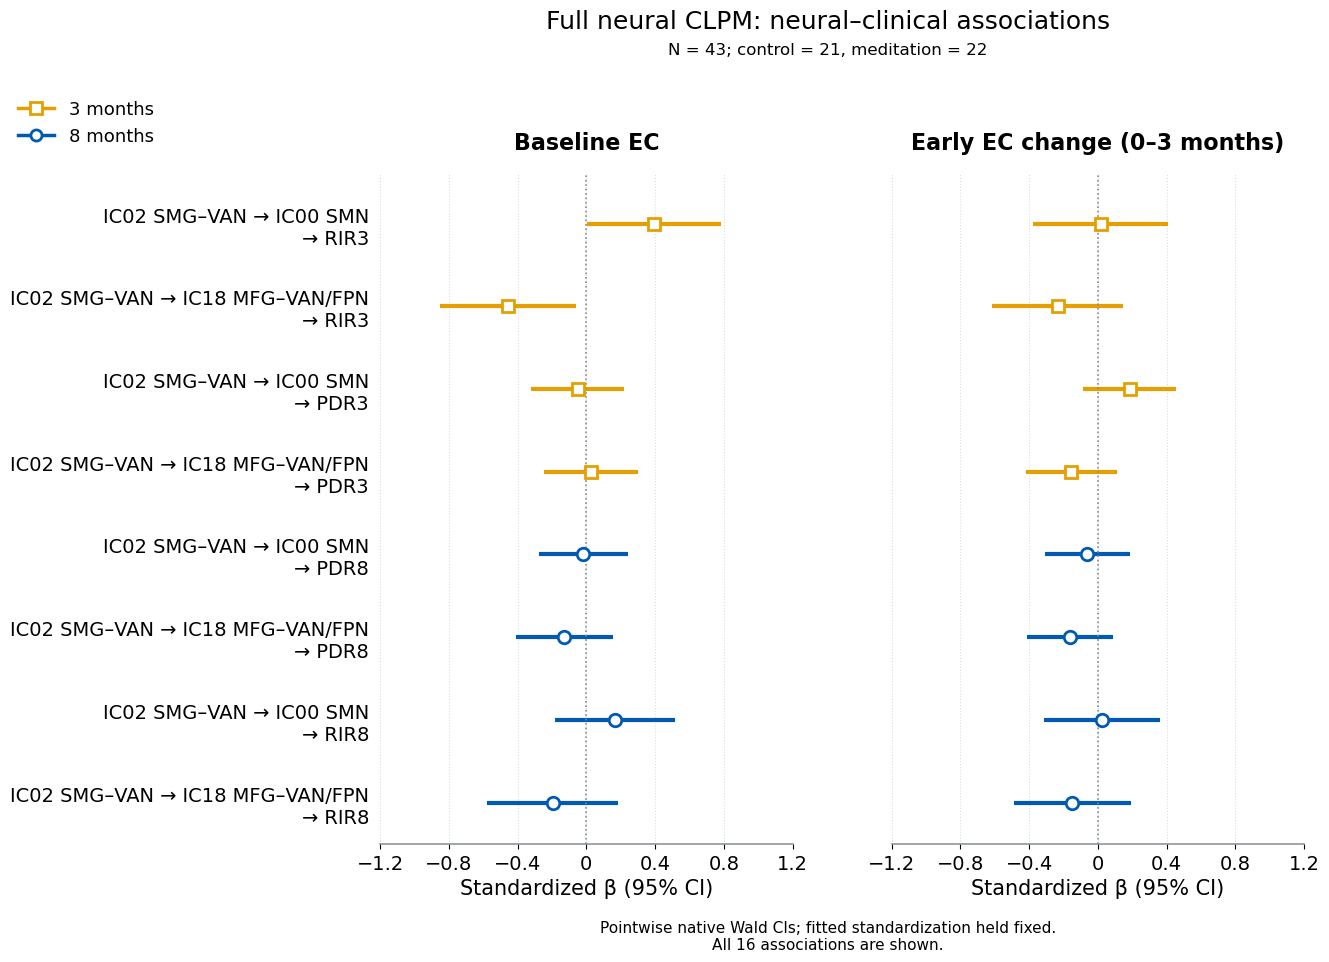

In [10]:
# Aim: reproduce the full-model neural coefficients; method: load the saved M3 beta and CI fields;
# output: the two-panel Figure 5b with all 16 associations and common readable x ticks.
fig5b_size = (14, 10)
fig5b_font = 15
fig5b_model = MODELS['M3']
fig5b_native = sem_paths.loc[sem_paths.Model.eq(fig5b_model) & sem_paths.op.eq('~')].set_index(['lval', 'rval'])
fig5b_keys = [(outcome, prefix + edge) for _, prefix in FAMILIES
              for outcome in NEURAL_OUTCOMES for edge, _ in NEURAL_EDGES]
fig5b_all = fig5b_native.loc[fig5b_keys]
fig5b_xlim, fig5b_ticks = common_limits(
    fig5b_all[['SEM_CI95_low_Beta_plugin', 'SEM_CI95_high_Beta_plugin']].to_numpy(), minimum=0.9)
fig5b_labels = [edge_label(nodes) + '\n→ ' + OUTCOME_LABELS[outcome]
                for outcome in NEURAL_OUTCOMES for _, nodes in NEURAL_EDGES]
fig, axes = plt.subplots(1, 2, figsize=fig5b_size, sharey=True)
fig.subplots_adjust(left=0.32, right=0.98, top=0.82, bottom=0.15, wspace=0.24)
for ax, (title, prefix) in zip(axes, FAMILIES):
    keys = [(outcome, prefix + edge) for outcome in NEURAL_OUTCOMES for edge, _ in NEURAL_EDGES]
    for j, row in enumerate(fig5b_native.loc[keys].reset_index().itertuples(index=False)):
        interval(ax, j, row.Beta, row.SEM_CI95_low_Beta_plugin,
                 row.SEM_CI95_high_Beta_plugin, int(row.lval[-1]), linewidth=3, markersize=9)
    ax.set_title(title, fontsize=fig5b_font + 1, fontweight='bold', pad=18)
    ax.set_xlim(fig5b_xlim)
    ax.set_xticks(fig5b_ticks)
    plain_ticks(ax)
    ax.axvline(0, color='#858b92', linestyle=':', linewidth=1.2)
    ax.set_xlabel('Standardized β (95% CI)', fontsize=fig5b_font)
    ax.tick_params(axis='x', labelsize=fig5b_font - 1)
    quiet_axes(ax)
axes[0].set_yticks(range(len(fig5b_labels)), fig5b_labels, fontsize=fig5b_font - 1)
axes[0].set_ylim(len(fig5b_labels) - 0.5, -0.6)
axes[1].tick_params(axis='y', labelleft=False)
fig.legend(handles=month_handles(), loc='upper left', bbox_to_anchor=(0.05, 0.91), frameon=False)
fig.suptitle('Full neural CLPM: neural–clinical associations', x=0.64, y=0.985, fontsize=18)
info = fig5b_all.iloc[0]
fig.text(0.64, 0.94, f'N = {int(info.N)}; control = {int(info.Control_N)}, meditation = {int(info.Meditation_N)}',
         ha='center', fontsize=12)
fig.text(0.64, 0.045, 'Pointwise native Wald CIs; fitted standardization held fixed.\nAll 16 associations are shown.',
         ha='center', fontsize=11)
save_panel(fig, 'Figure5b_full_neural_coefficients', 'Figure 5b', [FILES['paths'], FILES['names']],
           'Model=3_Two_early_changes; op=~; EC0_/D3_ of two focal ECs × four clinical outcomes',
           'Saved plug-in standardized native Wald intervals; no statistical-support filtering.')

## 11. Added in-sample information (Figure 5c)

Each total is **M3 − M1**, partitioned into baseline ECs (**M2 − M1**, hatched) and early EC
changes (**M3 − M2**, filled). These are sequential increments in conditional in-sample R²;
the decomposition depends on the order in which predictors enter the models. The source also
provides adjusted R², shown in the numeric table. No uncertainty interval for ΔR² is estimated.

,Baseline ECs,Early EC changes,Total ECs,Adjusted: Baseline ECs,Adjusted: Early EC changes,Adjusted: Total ECs
Outcome,,,,,,
PANSS_dec_rate_3,0.025356,0.022732,0.048087,0.007095,0.004537,0.011632
PANSS_dec_rate_8,0.000420,0.010709,0.011129,-0.020371,-0.008280,-0.028651
RBANS_inc_rate_3,0.124986,0.021798,0.146784,0.100751,-0.022089,0.078662
RBANS_inc_rate_8,0.012061,0.007801,0.019862,-0.022087,-0.031302,-0.053389


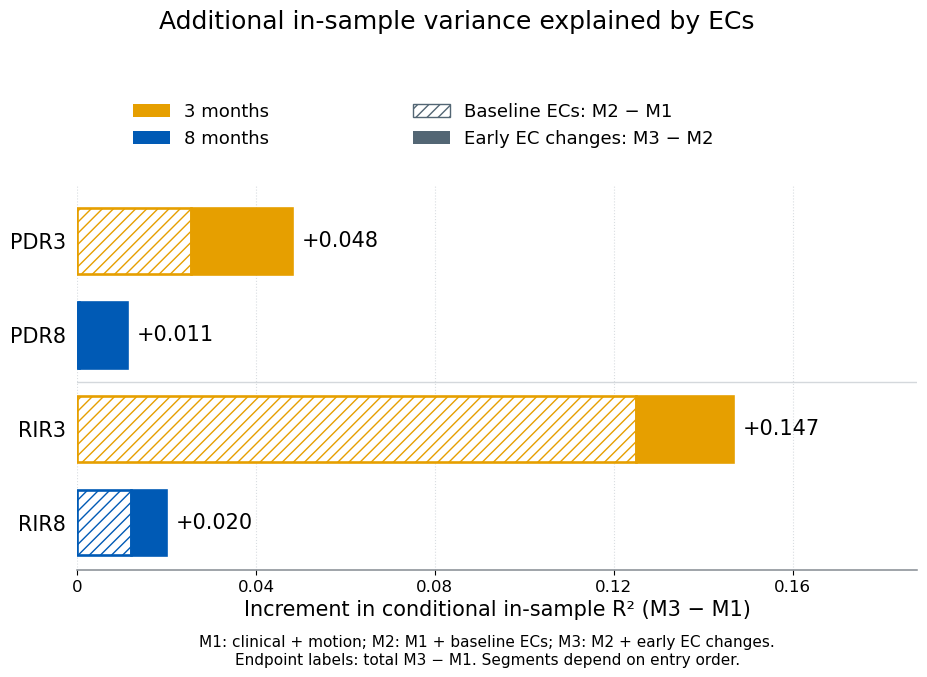

In [11]:
# Aim: reproduce the combined neural R² increment; method: subtract saved M1/M2/M3 outcomes;
# output: a stacked Figure 5c and numeric raw/adjusted-R² contribution table.
fig5c_size = (10, 7)
fig5c_font = 15
fig5c_order = ['PANSS_dec_rate_3', 'PANSS_dec_rate_8', 'RBANS_inc_rate_3', 'RBANS_inc_rate_8']
fig5c_r2 = sem_outcomes.pivot(index='Outcome', columns='Model', values='In_sample_R2')
fig5c_adj = sem_outcomes.pivot(index='Outcome', columns='Model', values='Adjusted_R2')
fig5c_added = pd.DataFrame(index=fig5c_order)
fig5c_added.index.name = 'Outcome'
for label, table in [('', fig5c_r2), ('Adjusted: ', fig5c_adj)]:
    fig5c_added[label + 'Baseline ECs'] = table[MODELS['M2']] - table[MODELS['M1']]
    fig5c_added[label + 'Early EC changes'] = table[MODELS['M3']] - table[MODELS['M2']]
    fig5c_added[label + 'Total ECs'] = table[MODELS['M3']] - table[MODELS['M1']]
display(fig5c_added)

def r2_number(value):
    if value == 0:
        return '0.000'
    if 0 < value < 0.001:
        return '<0.001'
    if -0.001 < value < 0:
        return '>−0.001'
    return f'{value:+.3f}'

# The current saved increments are nonnegative. Do not silently clip a revised negative increment.
if (fig5c_added[['Baseline ECs', 'Early EC changes']] < 0).any().any():
    raise ValueError('A sequential increment is negative: use a signed bridge display rather than this stacked-bar design.')
fig, ax = plt.subplots(figsize=fig5c_size)
fig.subplots_adjust(left=0.12, right=0.96, top=0.74, bottom=0.19)
for j, outcome in enumerate(fig5c_order):
    color = MONTH_COLORS[int(outcome[-1])]
    left = 0.0
    for k, label in enumerate(['Baseline ECs', 'Early EC changes']):
        value = float(fig5c_added.loc[outcome, label])
        ax.barh(j, value, left=left, height=0.70, facecolor='white' if k == 0 else color,
                edgecolor=color, linewidth=1.9, hatch='///' if k == 0 else None, zorder=3)
        left += value
    total = float(fig5c_added.loc[outcome, 'Total ECs'])
    ax.annotate(r2_number(total), (total, j), xytext=(7, 0), textcoords='offset points',
                va='center', ha='left', fontsize=fig5c_font)
extent = max(float(fig5c_added['Total ECs'].max()), 0.01)
ax.set_xlim(0, extent * 1.28)
ax.set_yticks(range(len(fig5c_order)), [OUTCOME_LABELS[o] for o in fig5c_order], fontsize=fig5c_font)
ax.set_ylim(3.5, -0.6)
ax.axhline(1.5, color='#d4d8dc', linewidth=1)
ax.set_xlabel('Increment in conditional in-sample R² (M3 − M1)', fontsize=fig5c_font)
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
plain_ticks(ax)
quiet_axes(ax)
fig.legend(handles=[Patch(facecolor=MONTH_COLORS[m], label=f'{m} months') for m in [3, 8]],
           loc='upper left', bbox_to_anchor=(0.16, 0.88), frameon=False, fontsize=13)
fig.legend(handles=[Patch(facecolor='white', edgecolor='#536674', hatch='///', label='Baseline ECs: M2 − M1'),
                    Patch(facecolor='#536674', label='Early EC changes: M3 − M2')],
           loc='upper left', bbox_to_anchor=(0.44, 0.88), frameon=False, fontsize=13)
fig.suptitle('Additional in-sample variance explained by ECs', fontsize=18, y=0.99)
fig.text(0.53, 0.055, 'M1: clinical + motion; M2: M1 + baseline ECs; M3: M2 + early EC changes.\n'
                    'Endpoint labels: total M3 − M1. Segments depend on entry order.', ha='center', fontsize=11)
save_panel(fig, 'Figure5c_EC_R2_contributions', 'Figure 5c', [FILES['outcomes']],
           'M2−M1 and M3−M2 stacked; endpoint M3−M1; In_sample_R2; all four outcomes',
           'Conditional in-sample fit; no ΔR² uncertainty or predictive validation.')

## 12. Optional omission **range summary**

Set `RUN_OMISSION_RANGE_SUMMARY=True` in block 1 to draw this additional display. A horizontal
segment spans the released minimum and maximum across usable omissions; a diamond marks the
full-sample coefficient. These segments are **influence ranges, not confidence intervals**.
The table supplies the usable count and opposite-sign count for every displayed path.
The original Figure 6's individual omission points are not available in the public summary.

In [12]:
# Aim: summarize participant-omission influence; method: plot released minima/maxima and full beta;
# output: a clearly named range-only display, never reconstructed or simulated omission points.
fig6_size = (14, 10)
if not RUN_OMISSION_RANGE_SUMMARY:
    print('Omission range-only display is off. Enable RUN_OMISSION_RANGE_SUMMARY in block 1 if wanted.')
    record('Figure 6: range-only alternative', 'optional_not_requested', [FILES['loo']],
           'M3 focal EC baseline/change × four outcomes', note='Not the original omission-point cloud.')
elif loo_summary is None:
    print('Omission range summary unavailable: no public summary table is present.')
    record('Figure 6: range-only alternative', 'missing_optional_input', [FILES['loo']], 'M3 focal paths')
else:
    fig6_table = loo_summary.loc[loo_summary.Model.eq(MODELS['M3'])].set_index(['lval', 'rval'])
    fig6_keys = [(outcome, prefix + edge) for _, prefix in FAMILIES
                 for outcome in NEURAL_OUTCOMES for edge, _ in NEURAL_EDGES]
    fig6_all = fig6_table.loc[fig6_keys]
    fig6_xlim, fig6_ticks = common_limits(fig6_all[['LOO_min_Beta', 'LOO_max_Beta', 'Full_Beta']].to_numpy(), minimum=0.9)
    fig6_labels = [edge_label(nodes) + '\n→ ' + OUTCOME_LABELS[outcome]
                   for outcome in NEURAL_OUTCOMES for _, nodes in NEURAL_EDGES]
    fig, axes = plt.subplots(1, 2, figsize=fig6_size, sharey=True)
    fig.subplots_adjust(left=0.32, right=0.98, top=0.80, bottom=0.16, wspace=0.24)
    for ax, (title, prefix) in zip(axes, FAMILIES):
        keys = [(outcome, prefix + edge) for outcome in NEURAL_OUTCOMES for edge, _ in NEURAL_EDGES]
        for j, row in enumerate(fig6_table.loc[keys].reset_index().itertuples(index=False)):
            color = MONTH_COLORS[int(row.lval[-1])]
            ax.hlines(j, row.LOO_min_Beta, row.LOO_max_Beta, color=color, linewidth=3, zorder=2)
            ax.plot(row.Full_Beta, j, marker='D', color=color, markerfacecolor='white',
                    markeredgewidth=2, markersize=8, linestyle='none', zorder=3)
        ax.set_title(title, fontweight='bold', pad=18)
        ax.set_xlim(fig6_xlim)
        ax.set_xticks(fig6_ticks)
        plain_ticks(ax)
        ax.axvline(0, color='#858b92', linestyle=':', linewidth=1.2)
        ax.set_xlabel('Standardized β')
        quiet_axes(ax)
    axes[0].set_yticks(range(len(fig6_labels)), fig6_labels, fontsize=14)
    axes[0].set_ylim(len(fig6_labels) - 0.5, -0.6)
    axes[1].tick_params(axis='y', labelleft=False)
    fig.suptitle('Participant-omission ranges — summary display', x=0.64, y=0.99, fontsize=18)
    fig.legend(handles=[Patch(facecolor=MONTH_COLORS[m], label=f'{m} months') for m in [3, 8]] + [
        Line2D([], [], marker='D', color='#536674', markerfacecolor='white', linestyle='none',
               markeredgewidth=2, label='Full-sample estimate'),
        Line2D([], [], color='#536674', linewidth=3, label='Min–max omission range'),
    ], loc='upper center', bbox_to_anchor=(0.64, 0.94), ncol=2, frameon=False)
    fig.text(0.64, 0.045, 'Ranges describe influence; they are not CIs.\n'
                        'Individual omission dots are not reconstructed from these summaries.', ha='center', fontsize=11)
    display(fig6_all.reset_index()[['lval', 'rval', 'N', 'LOO_requested', 'LOO_usable',
                                   'Full_Beta', 'LOO_min_Beta', 'LOO_max_Beta', 'LOO_opposite_sign_count']])
    save_panel(fig, 'Figure6_summary_ranges_ONLY', 'Figure 6: range-only alternative',
               [FILES['loo'], FILES['names']], 'M3; two focal EC baseline/change terms × four outcomes',
               'Distinct summary visualization; not the original 43-omission point display; ranges are not CIs.')

Omission range-only display is off. Enable RUN_OMISSION_RANGE_SUMMARY in block 1 if wanted.


## 13. Panel overview

In [13]:
# Summarize the panels drawn from the available aggregate tables.
figure_manifest = pd.DataFrame(provenance).drop_duplicates(
    subset=['Panel', 'Output_stem', 'Row_filter_or_transform'], keep='last')
display(figure_manifest[['Panel', 'Status', 'Output_stem', 'Note']])

,Panel,Status,Output_stem,Note
0,Figure 1: estimate summary,displayed_only,Figure1_ATE_estimate_summary,"Additional aggregate estimate display, not the..."
1,Figure 1: arm trajectories,displayed_only,Figure1_PDR_trajectories,Exported pointwise marginal-mean CIs; rates mu...
2,Figure 1: arm trajectories,displayed_only,Figure1_RIR_trajectories,Exported pointwise marginal-mean CIs; rates mu...
3,Figure 2b: coefficient panel,displayed_only,Figure2b_clinical_CLPM_coefficients,Diagram coefficients displayed as a forest pan...
4,Figure 2: mediation summary,displayed_table,,Saved OLS product/percentile bootstrap summary...
5,Figure 3b,displayed_only,Figure3b_intrinsic_network_contrasts,Saved pointwise native Wald intervals; existin...
6,Figure 3c: EC trajectory,displayed_only,Figure3c_IC02_to_IC00_FD_trajectory,Focal_edge flag supplies the reporting choice;...
7,Figure 3c: EC trajectory,displayed_only,Figure3c_IC02_to_IC18_FD_trajectory,Focal_edge flag supplies the reporting choice;...
8,Figure 4: EC contrast,displayed_only,Figure4_IC02_to_IC00_contrast,Full-PEB pointwise CrIs; not BMA or selection-...
9,Figure 4: EC contrast,displayed_only,Figure4_IC02_to_IC04_contrast,Full-PEB pointwise CrIs; not BMA or selection-...
